123

In [16]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pystac_client
import planetary_computer as pc
import stackstac
import rioxarray as rxr
import xarray as xr
import geopandas as gpd
from shapely.geometry import Point

# Microsoft JhengHei for Chinese labels
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "PingFang TC", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

# Connect to Planetary Computer
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)

def robust_search(bbox, datetime_range, cloud_max=30, max_items=60, tries=3):
    for attempt in range(tries):
        try:
            search = catalog.search(
                collections=["sentinel-2-l2a"],
                bbox=bbox,
                datetime=datetime_range,
                max_items=max_items,
            )
            items = list(search.items())
            items = [i for i in items if i.properties.get("eo:cloud_cover", 100) < cloud_max]
            items.sort(key=lambda i: i.properties["eo:cloud_cover"])
            return items
        except Exception as e:
            time.sleep(2 ** attempt)
    raise RuntimeError("STAC search failed 3x")

# AOI — Matai'an catchment (upper Wanrong → downstream Guangfu)
MATAIAN_BBOX = [121.28, 23.56, 121.52, 23.76]
WANTED_BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]


### Cell 2 -事前影像選擇（Act 1）
---

在指定時間範圍（2025-06-01 至 2025-07-15）與雲量門檻（20%）下，僅找到一張符合條件的 Sentinel-2 影像。儘管候選影像數量有限，該影像在馬太鞍溪谷研究區域內雲量極少，河道與周邊植被清晰可見，因此適合作為後續變化分析的事前基準影像。

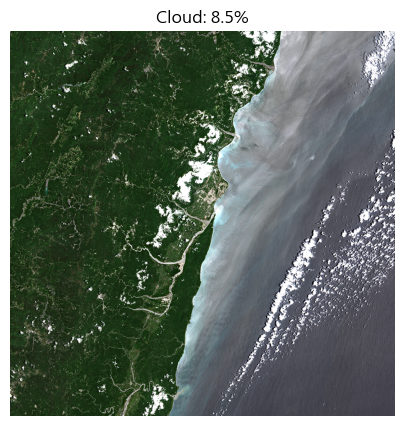

In [17]:
# [S2] ACT 1 — Pre-event STAC search (Jun 2025, before Typhoon Wipha)
# use robust_search() from S1 — MATAIAN_BBOX, "2025-06-01/2025-07-15", cloud_max=20
items_pre = robust_search(MATAIAN_BBOX, "2025-06-01/2025-07-15", cloud_max=20)

# TODO: TCI Quick-QA the top 3 candidates in a dynamic 1xN subplot grid
n = max(min(len(items_pre), 3), 1)
fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
if n == 1: axes = [axes]

for ax, item in zip(axes, items_pre[:n]):
    href = item.assets["visual"].href
    
    # 🔑 重要：要 sign（Planetary Computer）
    signed_href = pc.sign(href)
    
    img = rxr.open_rasterio(signed_href, overview_level=3)
    
    # 轉成 (H, W, 3)
    img = img.transpose("y", "x", "band")
    
    ax.imshow(img)
    ax.set_title(f"Cloud: {item.properties['eo:cloud_cover']:.1f}%")
    ax.axis("off")

# TODO: Pick your best scene and save the item ID
pre_item = items_pre[0]
PRE_ITEM_ID = pre_item.id

### Cell 4 - 事件中影像選擇（Act 2）
---
在候選影像中，選擇 2025-08-17 作為事件中影像。雖然整體雲量約為 17.6%，但馬太鞍溪谷上游區域仍具良好可視性，可觀察到河道局部變寬與混濁水體特徵，顯示堰塞湖的形成跡象。相較之下，其餘影像受雲層影響較大或關鍵區域不清晰，因此未被選用。

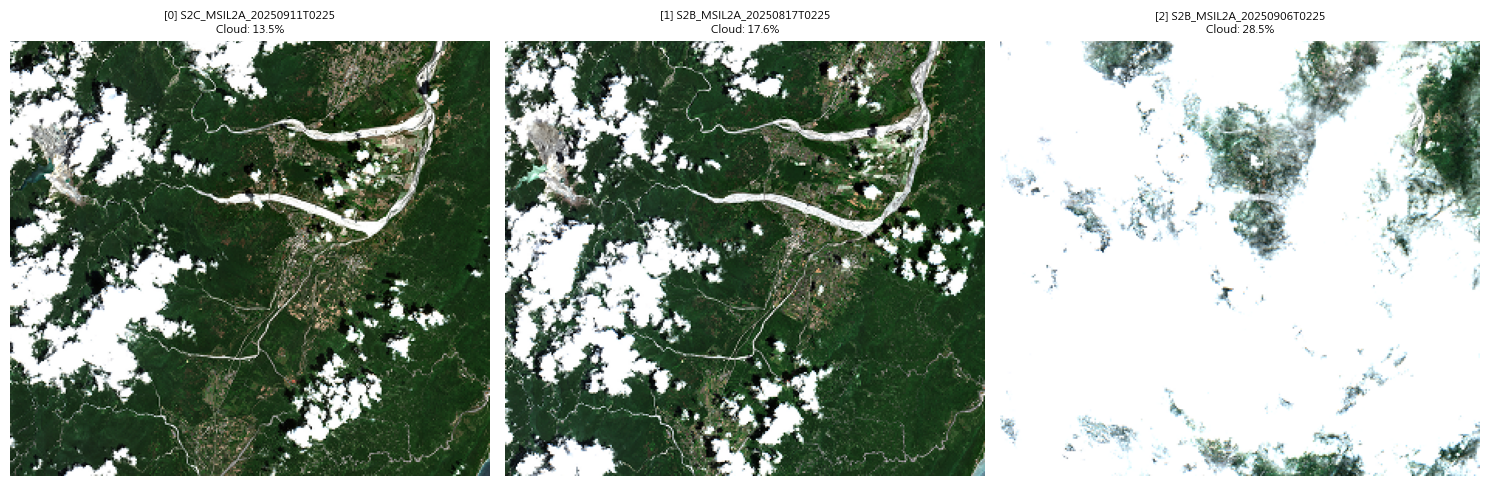

選定: [1] S2B_MSIL2A_20250817T022539_R046_T51QUG_20250817T042827
日期: 2025-08-17  雲量: 17.6%


In [18]:
# [S3] ACT 2 — Mid-event STAC search (Aug–Sep 2025, barrier lake present, before Sep 23 breach)
items_mid = robust_search(MATAIAN_BBOX, "2025-08-01/2025-09-20", cloud_max=40)

# TCI Quick-QA — cropped to AOI so the valley is visible
minx, miny, maxx, maxy = MATAIAN_BBOX  # [121.28, 23.56, 121.52, 23.76]

n = max(min(len(items_mid), 3), 1)
fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
if n == 1: axes = [axes]

for ax, item in zip(axes, items_mid[:n]):
    signed_href = pc.sign(item.assets["visual"].href)

    # overview_level=2 → 中等解析度，讀完再裁切到馬太鞍範圍
    img = rxr.open_rasterio(signed_href, overview_level=2)
    img_crop = img.rio.clip_box(minx=minx, miny=miny, maxx=maxx, maxy=maxy, crs="EPSG:4326")
    rgb = img_crop.transpose("y", "x", "band").values

    ax.imshow(rgb)
    ax.set_title(f"[{items_mid.index(item)}] {item.id[:24]}\nCloud: {item.properties['eo:cloud_cover']:.1f}%",
                 fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 看完上面的圖，填入你選的 index（0、1 或 2）
CHOSEN_MID_IDX = 1   # ← 改這裡
mid_item    = items_mid[CHOSEN_MID_IDX]
MID_ITEM_ID = mid_item.id
print(f"選定: [{CHOSEN_MID_IDX}] {MID_ITEM_ID}")
print(f"日期: {mid_item.properties['datetime'][:10]}  雲量: {mid_item.properties['eo:cloud_cover']:.1f}%")


### Cell 5 - 事件後影像選擇（Act 3）
---
在候選影像中，選擇 2025-10-01 作為事件後影像。選擇這張影像是因為在上游山谷中可以清楚看到一塊連續的藍綠色水體，顯示堰塞湖的形成，且雲量較低、不影響判讀。相比其他影像，這張最能明顯呈現濁水範圍與湖體形狀。

選定: [2] S2B_MSIL2A_20251006T022529_R046_T51QUG_20251006T042653
日期: 2025-10-06  雲量: 13.3%


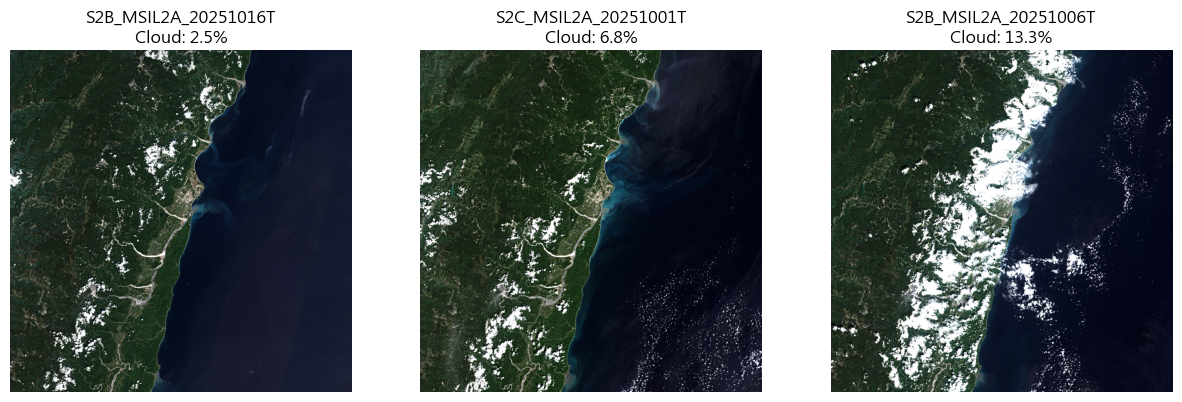

In [19]:
# [S4] ACT 3 — Post-event STAC search (after Sep 23 breach)
# TODO: robust_search for 2025-09-25/2025-11-15, cloud_max=30
items_post = robust_search(MATAIAN_BBOX, "2025-09-25/2025-11-15", cloud_max=30)

# TODO: TCI Quick-QA top 3 — look for evidence of the drained lake bed + fresh sediment around Guangfu
n = max(min(len(items_post), 3), 1)
fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
if n == 1: axes = [axes]

for ax, item in zip(axes, items_post[:n]):
    href = item.assets["visual"].href
    signed_href = pc.sign(href)
    
    img = rxr.open_rasterio(signed_href, overview_level=3)
    img = img.transpose("y", "x", "band")
    
    ax.imshow(img)
    ax.set_title(f"{item.id[:20]}\nCloud: {item.properties['eo:cloud_cover']:.1f}%")
    ax.axis("off")

# 看完上面的圖，填入你選的 index（0、1 或 2）
CHOSEN_POST_IDX = 2   # ← 改這裡
post_item    = items_post[CHOSEN_POST_IDX]
POST_ITEM_ID = post_item.id
print(f"選定: [{CHOSEN_POST_IDX}] {POST_ITEM_ID}")
print(f"日期: {post_item.properties['datetime'][:10]}  雲量: {post_item.properties['eo:cloud_cover']:.1f}%")


### Cell 6 - 影像資料載入與預處理
---
本步驟使用 `stream_cube()` 函數從 STAC 讀取 Sentinel-2 影像資料，並透過 Planetary Computer 重新簽名以避免存取權限過期。資料以 `stackstac` 轉換為 xarray 資料結構，並限制於馬太鞍溪谷研究範圍，以提升運算效率。影像統一轉換至 UTM 座標系（EPSG:32651）與 10 公尺解析度，並將原始數值轉換為反射率（/10000）。

接著，利用 `composite_stretched()` 將選定波段組合為 RGB 影像，並透過百分位拉伸（2–98%）提升影像對比，使地表特徵（如水體、植被與裸地）更易於辨識。

最終分別建立事件前（Pre）、事件中（Mid）與事件後（Post）的影像資料集，作為後續變化分析與災害判釋的基礎。

In [20]:
def stream_cube(item, bands=WANTED_BANDS, bbox=MATAIAN_BBOX):
    # 每次都重新簽名（避免 token 過期）
    signed = pc.sign(item)
    
    # 用 stackstac 把 STAC 變成 xarray cube
    cube = stackstac.stack(
        [signed],
        assets=bands,
        epsg=32651,              # 台灣UTM座標
        resolution=10,           # 10m解析度
        bounds_latlon=bbox,      # 限定範圍（加速）
        chunksize=2048           # dask chunk（避免爆記憶體）
    )
    
    # 移除 time 維度（因為只有一張）
    cube = cube.squeeze("time")
    
    # 轉 reflectance（Sentinel-2 原始值要 /10000）
    cube = cube / 10000.0
    
    return cube

def composite_stretched(cube, r, g, b, lo=2, hi=98):
    # 組 RGB
    rgb = np.stack([
        cube.sel(band=r),
        cube.sel(band=g),
        cube.sel(band=b)
    ], axis=-1)
    
    out = np.zeros_like(rgb, dtype=np.float32)
    
    # 每個通道做 percentile stretch
    for k in range(3):
        p_lo, p_hi = np.nanpercentile(rgb[..., k], [lo, hi])
        
        out[..., k] = np.clip(
            (rgb[..., k] - p_lo) / (p_hi - p_lo),
            0, 1
        )
    
    return out.astype(np.float32)

cube_pre  = stream_cube(pre_item)
cube_mid  = stream_cube(mid_item)
cube_post = stream_cube(post_item)

### Cell 8 - 變化指標定義（Change Metrics）
---
本研究定義四種光譜變化指標，用於辨識水體、植被與裸地變化，進而分析災害影響：

- **NIR Drop（近紅外下降）**  
  定義：`pre(B08) - post(B08)`  
  說明：近紅外反射值下降通常代表植被減少或水體增加，可用於偵測淹水或植被破壞。

- **SWIR Post（短波紅外）**  
  定義：`post(B12)`  
  說明：短波紅外對土壤濕度與裸地敏感，可用於辨識崩塌區或濕潤土壤。

- **BSI（Bare Soil Index，裸地指標）**  
  定義：`((B11 + B04) - (B08 + B02)) / ((B11 + B04) + (B08 + B02))`  
  說明：數值越高代表裸地或土壤比例越高，常用於偵測崩塌與沉積區。

- **BSI Change（裸地變化）**  
  定義：`BSI(post) - BSI(pre)`  
  說明：正值代表裸地增加，可能對應沖刷或土石堆積。

- **NDVI（Normalized Difference Vegetation Index，植被指數）**  
  定義：`(B08 - B04) / (B08 + B04)`  
  說明：數值越高代表植被越茂密。

- **NDVI Change（植被變化）**  
  定義：`NDVI(post) - NDVI(pre)`  
  說明：負值代表植被減少，可能與崩塌或淹水有關。

這些指標將用於後續災害偵測（堰塞湖、崩塌與土石流）之判斷依據。

In [22]:
# Four reusable change metric functions
def nir_drop(pre, post):
    # TODO: return pre.sel(band="B08") - post.sel(band="B08")
    return pre.sel(band="B08") - post.sel(band="B08")

def swir_post(post):
    # TODO: return post.sel(band="B12")
    return post.sel(band="B12")

def bsi(cube):
    # TODO: BSI = ((B11 + B04) - (B08 + B02)) / ((B11 + B04) + (B08 + B02))
    # Bare Soil Index（裸地指標）
    B11 = cube.sel(band="B11")
    B04 = cube.sel(band="B04")
    B08 = cube.sel(band="B08")
    B02 = cube.sel(band="B02")
    return ((B11 + B04) - (B08 + B02)) / ((B11 + B04) + (B08 + B02))

def bsi_change(pre, post):
    # TODO: return bsi(post) - bsi(pre)
    # 裸地變化（增加 = 可能沖刷/沉積）
    return bsi(post) - bsi(pre)

def ndvi(cube):
    # TODO: (B08 - B04) / (B08 + B04)
    # 植被指數
    B08 = cube.sel(band="B08")
    B04 = cube.sel(band="B04")
    return (B08 - B04) / (B08 + B04)

def ndvi_change(pre, post):
    # TODO: return ndvi(post) - ndvi(pre)
    # 植被減少
    return ndvi(post) - ndvi(pre)

### Cell 9 - 堰塞湖偵測（Barrier Lake Detection）
---
本步驟利用 Pre 與 Mid 影像之光譜變化，偵測上游堰塞湖的形成。首先選取近紅外（NIR）、藍光（Blue）與綠光（Green）波段，建立水體判別條件。由於堰塞湖為混濁水體，其近紅外反射值低於植被，但高於清水，因此設定多組 NIR 閾值（0.12、0.15、0.18）進行測試。

同時，透過經度門檻（121.33°E）限制分析範圍於上游區域，以避免將下游淹水誤判為堰塞湖。對每組閾值計算水體面積，並與 NCDR 參考值（約 0.86 km²）比較，選擇最接近者作為最佳閾值。

最終生成堰塞湖遮罩（lake mask），並疊加於影像上進行視覺驗證，確認偵測結果與實際地形變化一致。

In [ ]:
import os
from pyproj import Transformer

os.makedirs("output", exist_ok=True)

# [S7] Barrier lake detection
nir_pre   = cube_pre.sel(band="B08")
nir_mid   = cube_mid.sel(band="B08")
blue_mid  = cube_mid.sel(band="B02")
green_mid = cube_mid.sel(band="B03")

# 把 121.33°E 轉換成 UTM x（公尺），確保座標系一致
tf = Transformer.from_crs("EPSG:4326", "EPSG:32651", always_xy=True)
x_gate, _ = tf.transform(121.33, 23.69)

# 直接用 xarray 的 x 座標做空間篩選（自動廣播到整張影像，不用 np.tile）
west_mask = cube_mid.x < x_gate

# --- 閥值測試 ---
lake_results = {}
for thr in [0.12, 0.15, 0.18, 0.20, 0.22]:
    mask = (
        (nir_pre   > 0.25) &   # 原本是植被
        (nir_mid   < thr)  &   # 變成水體
        (blue_mid  > 0.03) &   # 水的藍光特徵
        (green_mid > nir_mid) & # 水的光譜形狀
        west_mask              # 限制在上游（121.33°E 以西）
    )
    area_km2 = float(mask.sum().compute()) * 100 / 1e6
    lake_results[thr] = area_km2
    print(f"thr={thr}: {area_km2:.3f} km²")

# 選最接近 NCDR 參考值 0.86 km² 的閥值
best_thr = min(lake_results, key=lambda k: abs(lake_results[k] - 0.86))
print(f"\nBest threshold: {best_thr}  ({lake_results[best_thr]:.3f} km²)")

# --- 建立最終 lake_mask 並 compute ---
lake_mask = (
    (nir_pre   > 0.25) &
    (nir_mid   < best_thr) &
    (blue_mid  > 0.03) &
    (green_mid > nir_mid) &
    west_mask
).compute()

# --- 繪圖 ---
rgb_mid = composite_stretched(cube_mid, "B04", "B03", "B02")

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("ACT 1→2 Barrier lake detection — NCDR ref ≈0.86 km²")

ax[0].imshow(rgb_mid)
ax[0].set_title("Mid-event TCI")
ax[0].axis("off")

ax[1].imshow(rgb_mid)
ax[1].imshow(np.where(lake_mask.values, 1, np.nan), cmap="cool", alpha=0.5)
ax[1].set_title(f"Lake mask  thr={best_thr}  {lake_results[best_thr]:.3f} km²")
ax[1].axis("off")

plt.tight_layout()
plt.savefig("output/07_lake_mask.png", dpi=150)
plt.show()
